In [1]:
print("Helo, Zambia")

Helo, Zambia


In [2]:
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
# ---- House style --------------------------------------------------------
plt.rcParams.update({
"figure.figsize": (9, 4.5),
"figure.dpi": 110,
"figure.facecolor": "#fcfcfb",
"axes.facecolor": "#fcfcfb",
"axes.edgecolor": "#c3c2b7",
"axes.labelcolor": "#52514e",
"axes.titlesize": 13,
"axes.titleweight": "bold",
"axes.titlelocation": "left",
"axes.spines.top": False,
"axes.spines.right": False,
"axes.grid": True,
"axes.grid.axis": "y",
"grid.color": "#e1e0d9",
"grid.linewidth": 0.8,
"xtick.color": "#898781",
"ytick.color": "#898781",
"font.size": 10,
"legend.frameon": False,
"lines.linewidth": 2,
})
# ---- Palette ------------------------------------------------------------
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREY, GREY_LIGHT = "#898781", "#d6d5cf"
INK, INK_SOFT = "#0b0b0b", "#52514e"
SERIES = [BLUE, ORANGE, AQUA, YELLOW]
# fixed order, never cycled
print("Matplotlib", plt.matplotlib.__version__, "| pandas", pd.__version__)

Matplotlib 3.11.2 | pandas 3.1.0


In [3]:
with open("zambia_synthetic_climate_2021_2025.json") as f:
  data = json.load(f)
print(data["metadata"]["title"])
print("Period:", data["metadata"]["period"])
print("Sections:", list(data.keys()))
provinces = pd.DataFrame(data["provinces"])
monthly = pd.DataFrame(data["monthly"])
annual = pd.DataFrame(data["annual"])
monthly["date"] = pd.to_datetime(monthly["date"])
print(f"\nmonthly: {monthly.shape}, annual: {annual.shape}, provinces: {provinces.shape}")
monthly.head()

Synthetic Zambia climate, population and air-quality dataset
Period: 2021-01 to 2025-12
Sections: ['metadata', 'provinces', 'monthly', 'annual']

monthly: (600, 14), annual: (50, 7), provinces: (10, 4)


,province,year,month,month_name,date,rainfall_mm,rainy_days,temp_mean_c,temp_max_c,temp_min_c,humidity_pct,pm25_ugm3,so2_ugm3,air_quality_category
0,Central,2021,1,Jan,2021-01-01,232.9,21,21.7,28.0,15.1,73.4,13.0,6.1,Moderate
1,Central,2021,2,Feb,2021-02-01,208.4,17,22.5,30.4,15.0,64.6,11.6,6.3,Good
2,Central,2021,3,Mar,2021-03-01,190.8,18,21.5,29.2,13.8,68.5,12.3,5.4,Moderate
3,Central,2021,4,Apr,2021-04-01,58.9,5,21.8,29.1,15.6,33.5,14.6,6.1,Moderate
4,Central,2021,5,May,2021-05-01,4.7,1,19.3,28.2,12.2,32.5,21.1,5.7,Moderate


In [4]:
annual.head()

,province,year,population,urban_population_pct,total_rainfall_mm,mean_temp_c,mean_pm25_ugm3
0,Central,2021,1945544,27.1,1012.3,21.04,19.6
1,Central,2022,2009197,29.7,1028.8,21.32,19.3
2,Central,2023,2064540,17.6,1001.4,21.48,20.3
3,Central,2024,2134243,23.8,553.8,21.93,22.4
4,Central,2025,2189284,16.9,1046.0,21.51,20.0


PART 3 Build the charts

The pattern behind every chart
1. fig, ax = plt.subplots() creates a Figure (the whole canvas) and an Axes (one plot area on it).
2. A method on ax draws the data: ax.plot, ax.bar, ax.scatter and so on.
3. Further ax.set_... methods add the title, axis labels and limits.
4. plt.show() displays the finished figure.
Calling methods on ax is called the object-oriented style. Older tutorials use plt.plot(...) directly;
it works for one plot but becomes confusing as soon as a figure has several.

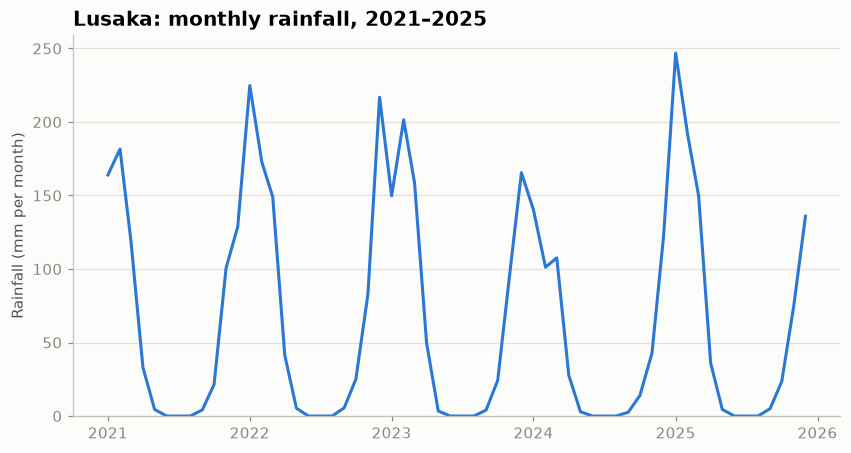

In [5]:
lusaka = monthly[monthly["province"] == "Lusaka"]
fig, ax = plt.subplots()
# 1. create the canvas and one Axes
ax.plot(lusaka["date"], lusaka["rainfall_mm"], color=BLUE)
# 2. draw the data
ax.set_title("Lusaka: monthly rainfall, 2021–2025")
# 3. label it
ax.set_ylabel("Rainfall (mm per month)")
ax.set_ylim(bottom=0)
# rainfall can't be negative; start at zero
plt.show()

### Interpretation: Lusaka Monthly Rainfall

**Purpose:** This line chart shows how monthly rainfall changes
in Lusaka between 2021 and 2025 in the supplied synthetic dataset.

**Observed pattern:** Rainfall follows a repeating seasonal
pattern, with high-rainfall periods separated by months with
little or no rainfall.

**Specific observation:** [Identify one year or period that
stands out and describe what you observe.]

**Design choice:** A line chart makes it easy to follow rainfall
over time and compare the timing and height of seasonal peaks.

**Limitation:** These are synthetic teaching data. The chart
does not establish actual rainfall conditions in Lusaka.

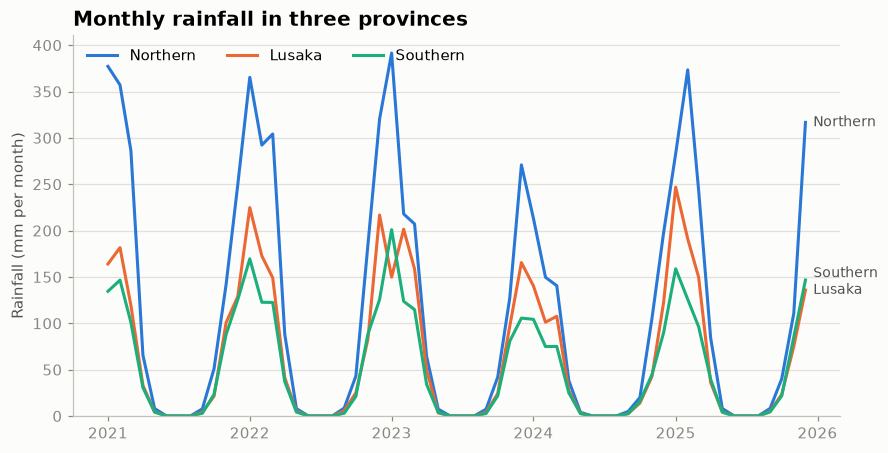

In [6]:
chosen = ["Northern", "Lusaka", "Southern"]
fig, ax = plt.subplots()
ends = []
for name, colour in zip(chosen, SERIES):
  sub = monthly[monthly["province"] == name]
  ax.plot(sub["date"], sub["rainfall_mm"], color=colour, label=name)
  ends.append([sub["rainfall_mm"].iloc[-1], name])
# Direct labels at the right-hand end. Lines can finish close together,
# so push labels apart until they are at least 18 mm apart vertically.
ends.sort()
for i in range(1, len(ends)):
  ends[i][0] = max(ends[i][0], ends[i - 1][0] + 18)
x_label = monthly["date"].max() + pd.Timedelta(days=20)
for y, name in ends:
  ax.text(x_label, y, name, color=INK_SOFT, va="center", fontsize=9)
ax.set_title("Monthly rainfall in three provinces")
ax.set_ylabel("Rainfall (mm per month)")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", ncols=3)
plt.show()

### Interpretation: Rainfall Across Three Provinces

**Purpose:** This chart compares monthly rainfall in Northern,
Lusaka, and Southern provinces from 2021 to 2025.

**Observed pattern:** Northern Province generally has the highest
rainfall peaks, Lusaka is usually intermediate, and Southern
Province generally has the lowest peaks. The three provinces
also show similar seasonal timing, with recurring wet and dry
periods.

**Insight:** The chart reveals differences in rainfall amounts
alongside a shared seasonal pattern.

**Design choice:** Plotting the three lines on the same axes
allows direct comparison using a common rainfall scale.

**Limitation:** Overlapping lines can make individual values
difficult to read. These synthetic data illustrate patterns
and should not be treated as actual provincial measurements.


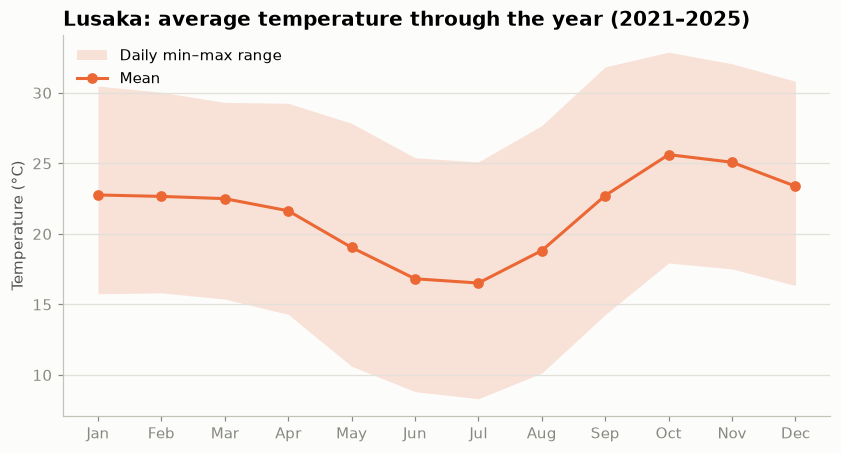

Hottest month: Oct
Coolest month: Jul


In [7]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
lsk_cycle = (monthly[monthly["province"] == "Lusaka"]
            .groupby("month")[["temp_mean_c", "temp_min_c", "temp_max_c"]]
            .mean())
fig, ax = plt.subplots()
ax.fill_between(lsk_cycle.index, lsk_cycle["temp_min_c"], lsk_cycle["temp_max_c"],
            color=ORANGE, alpha=0.18, linewidth=0, label="Daily min–max range")
ax.plot(lsk_cycle.index, lsk_cycle["temp_mean_c"], color=ORANGE,
     marker="o", markersize=6, label="Mean")
ax.set_xticks(range(1, 13), month_names)
ax.set_title("Lusaka: average temperature through the year (2021–2025)")
ax.set_ylabel("Temperature (°C)")
ax.legend(loc="upper left")
plt.show()
print("Hottest month:", month_names[lsk_cycle["temp_mean_c"].idxmax() - 1])
print("Coolest month:", month_names[lsk_cycle["temp_mean_c"].idxmin() - 1])

### Interpretation: Lusaka’s Seasonal Temperature Pattern

**Purpose:** This chart shows Lusaka’s average temperature
pattern by calendar month, using synthetic data from 2021–2025.

**Observed pattern:** Mean temperature is lowest in July and
highest in October. Temperatures generally decrease toward
the middle of the year before rising toward October.

**Design choice:** The line represents mean temperature.
The shaded band extends between the average monthly minimum
and maximum temperatures. It shows the temperature range
rather than statistical uncertainty.

**Insight:** Averaging the same calendar months across five
years makes the seasonal pattern easier to identify.

**Limitation:** Averaging hides differences between individual
years. These synthetic values are not actual weather records.

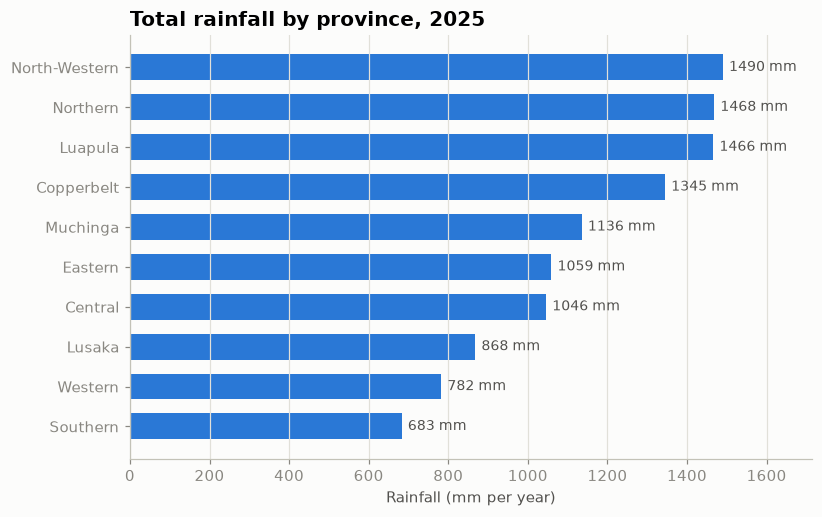

In [8]:
rain_2025 = (annual[annual["year"] == 2025]
            .sort_values("total_rainfall_mm"))
# ascending: largest ends up on top
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(rain_2025["province"], rain_2025["total_rainfall_mm"], color=BLUE, height=0.65)
ax.bar_label(bars, fmt="%.0f mm", padding=4, color=INK_SOFT, fontsize=9)
ax.set_title("Total rainfall by province, 2025")
ax.set_xlabel("Rainfall (mm per year)")
ax.grid(axis="y", visible=False)
# horizontal bars: gridlines on x instead
ax.grid(axis="x", visible=True)
ax.set_xlim(0, rain_2025["total_rainfall_mm"].max() * 1.15)
# room for the labels
plt.show()

### Interpretation: Total Rainfall by Province in 2025

**Purpose:** This horizontal bar chart compares total annual
rainfall across Zambia’s ten provinces in the synthetic
2025 dataset.

**Observed pattern:** North-Western Province has the highest
total rainfall, at approximately 1,490 mm. Southern Province
has the lowest, at approximately 683 mm. The highest total
is more than twice the lowest.

**Design choice:** Sorting the horizontal bars makes the
ranking easy to follow. Labels show the rainfall amounts,
while the common zero baseline supports fair comparison.

**Limitation:** Annual totals hide differences in when rain
falls during the year. These synthetic values should not
be interpreted as actual provincial rainfall measurements.

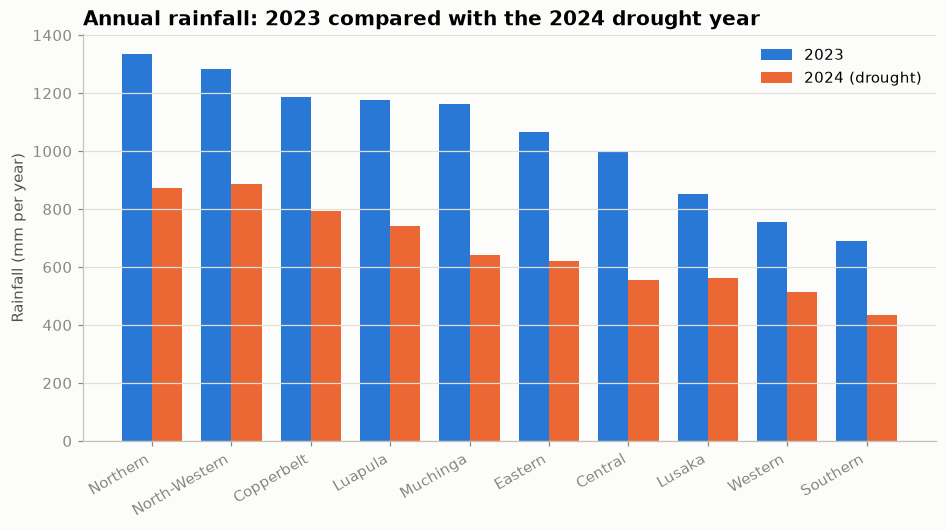

Average fall in rainfall, 2023 → 2024: 37%


In [9]:
wide = (annual[annual["year"].isin([2023, 2024])]
      .pivot(index="province", columns="year", values="total_rainfall_mm")
      .sort_values(2023, ascending=False))
x = np.arange(len(wide))
w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(x - w / 2, wide[2023], width=w, color=BLUE, label="2023")
ax.bar(x + w / 2, wide[2024], width=w, color=ORANGE, label="2024 (drought)")
ax.set_xticks(x, wide.index, rotation=30, ha="right")
ax.set_ylabel("Rainfall (mm per year)")
ax.set_title("Annual rainfall: 2023 compared with the 2024 drought year")
ax.legend(loc="upper right")
plt.show()
drop = (1 - wide[2024] / wide[2023]) * 100
print("Average fall in rainfall, 2023 → 2024:", f"{drop.mean():.0f}%")

### Interpretation: Provincial Rainfall in 2023 and 2024

**Purpose:** This grouped bar chart compares each province’s
annual rainfall in 2023 and 2024 using synthetic data.

**Observed pattern:** Every province has lower rainfall in
2024 than in 2023. The average of the ten provincial
percentage decreases is approximately 37%.

**Insight:** The simulated rainfall reduction affects all
provinces, although the size of the decrease varies.

**Design choice:** Placing the two years’ bars side by side
makes comparisons within each province straightforward.
Consistent colours distinguish the years.

**Limitation:** Annual totals hide monthly rainfall patterns.
The 37% figure is an unweighted average of provincial
percentage decreases, rather than an area-weighted national
rainfall reduction. These are synthetic teaching data.

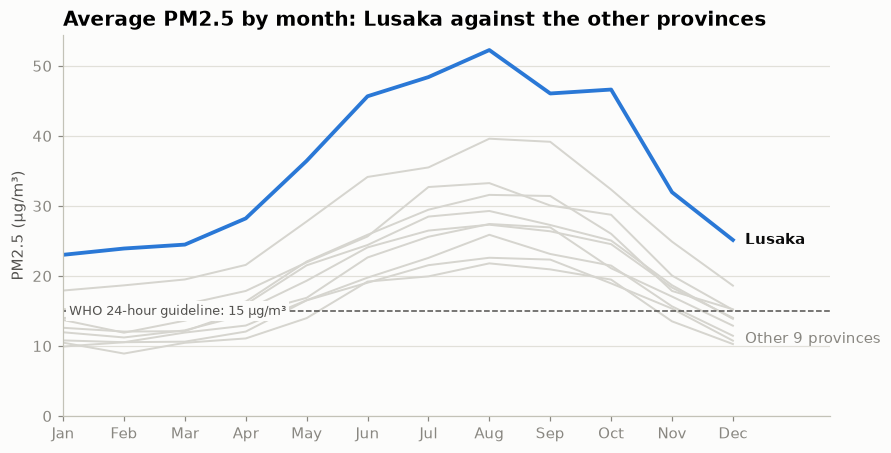

In [10]:
pm_cycle = monthly.groupby(["province", "month"])["pm25_ugm3"].mean().unstack(0)
focus = "Lusaka"
fig, ax = plt.subplots()
for name in pm_cycle.columns:
   if name != focus:
      ax.plot(pm_cycle.index, pm_cycle[name], color=GREY_LIGHT, linewidth=1.3)
ax.plot(pm_cycle.index, pm_cycle[focus], color=BLUE, linewidth=2.5)
ax.text(12.2, pm_cycle[focus].iloc[-1], focus, color=INK, va="center", fontweight="bold")
ax.text(12.2, 11, "Other 9 provinces", color=GREY, va="center")
ax.axhline(15, color=INK_SOFT, linestyle="--", linewidth=1)
# bbox= draws a small background box so the text stays readable over the grey lines
ax.text(1.1, 15, "WHO 24-hour guideline: 15 µg/m³", color=INK_SOFT, fontsize=8.5,
        va="center", bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=2))
ax.set_xticks(range(1, 13), month_names)
ax.set_xlim(1, 13.6)
ax.set_ylim(bottom=0)
ax.set_title("Average PM2.5 by month: Lusaka against the other provinces")
ax.set_ylabel("PM2.5 (µg/m³)")
plt.show()

### Interpretation: Seasonal PM2.5 Patterns

**Purpose:** This chart compares Lusaka’s average monthly
PM2.5 concentrations with those of the other nine provinces,
using synthetic data from 2021–2025.

**Observed pattern:** Lusaka’s concentration peaks in August.
Its highlighted line generally remains above the other
provinces, with higher concentrations during the middle
and later parts of the dry season.

**Design choice:** Highlighting Lusaka in blue while showing
other provinces in grey makes its seasonal pattern easy
to follow while retaining context for comparison.

**Limitation:** Averaging across five years hides variation
between years. Monthly averages cannot establish whether
a 24-hour air-quality guideline was exceeded on individual
days. These synthetic values are not actual pollution
measurements.

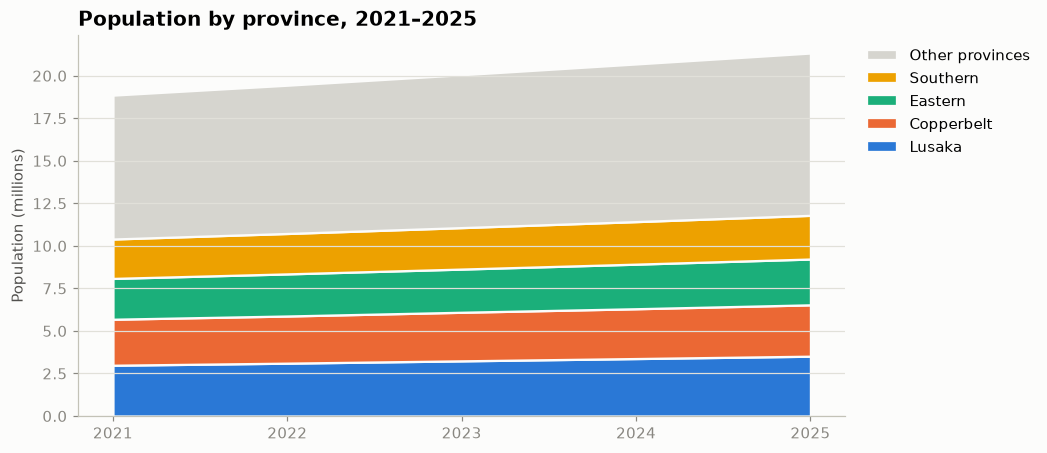

Total population: 18.9 m (2021) → 21.3 m (2025)


In [11]:
pop = annual.pivot(index="year", columns="province", values="population") / 1e6
top4 = pop.iloc[-1].sort_values(ascending=False).index[:4]
pop_plot = pop[top4].copy()
pop_plot["Other provinces"] = pop.drop(columns=top4).sum(axis=1)
fig, ax = plt.subplots()
ax.stackplot(pop_plot.index, pop_plot.T.values, labels=pop_plot.columns,
            colors=SERIES + [GREY_LIGHT], edgecolor="#fcfcfb", linewidth=1.5)
ax.set_xticks(pop_plot.index)
ax.set_ylabel("Population (millions)")
ax.set_title("Population by province, 2021–2025")
# reverse=True lists the legend in the same top-to-bottom order as the bands
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), reverse=True)
plt.show()
total = pop.sum(axis=1)
print(f"Total population: {total.iloc[0]:.1f} m (2021) → {total.iloc[-1]:.1f} m (2025)")

### Interpretation: Population Growth and Provincial Contributions

**Purpose:** This stacked area chart shows total population
and provincial contributions from 2021 to 2025 in the
synthetic dataset.

**Observed pattern:** Total population increases from about
18.9 million to 21.3 million, a rise of approximately
2.4 million. The overall height of the stacked areas
shows this upward trend.

**Design choice:** Coloured bands represent the four largest
provinces by population in 2025. The remaining six provinces
are combined as “Other provinces”. Each band’s thickness
represents its population contribution.

**Limitation:** Combining six provinces hides their individual
patterns. Bands without a common baseline are harder to
compare precisely. These are synthetic population figures,
not official census estimates.

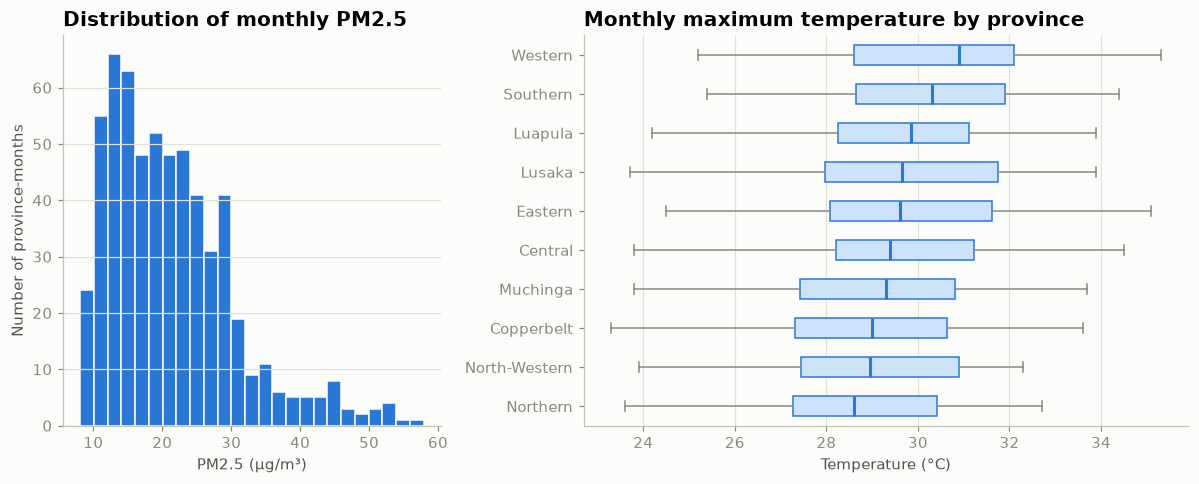

In [12]:
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(11, 4.5),
    width_ratios=[1, 1.6]
)

# Histogram of all monthly PM2.5 values
ax1.hist(
    monthly["pm25_ugm3"],
    bins=25,
    color=BLUE,
    edgecolor="#fcfcfb"
)

ax1.set_title("Distribution of monthly PM2.5")
ax1.set_xlabel("PM2.5 (µg/m³)")
ax1.set_ylabel("Number of province-months")

# Box plot of maximum temperature, provinces ordered by median
order = (
    monthly.groupby("province")["temp_max_c"]
    .median()
    .sort_values()
    .index
)

groups = [
    monthly.loc[monthly["province"] == p, "temp_max_c"]
    for p in order
]

ax2.boxplot(
    groups,
    tick_labels=order,
    orientation="horizontal",
    patch_artist=True,
    boxprops=dict(
        facecolor="#cde2fb",
        edgecolor=BLUE
    ),
    medianprops=dict(
        color=BLUE,
        linewidth=2
    ),
    whiskerprops=dict(color=GREY),
    capprops=dict(color=GREY),
    flierprops=dict(
        marker="o",
        markersize=4,
        markerfacecolor=GREY,
        markeredgecolor="none"
    )
)

ax2.set_title("Monthly maximum temperature by province")
ax2.set_xlabel("Temperature (°C)")

ax2.grid(axis="y", visible=False)
ax2.grid(axis="x", visible=True)

fig.tight_layout()
plt.show()

### Interpretation: PM2.5 Distribution and Maximum Temperatures

**Purpose:** These charts summarize the distribution of monthly
PM2.5 concentrations and compare monthly maximum temperatures
across provinces in the synthetic 2021–2025 dataset.

**Histogram:** Most PM2.5 observations fall around 10–30 µg/m³.
Higher concentrations occur less frequently, producing a
long tail to the right. Each observation represents one
province in one month.

**Box plots:** Western Province has the highest median monthly
maximum temperature, while Northern Province has the lowest.
The overlapping boxes indicate that provincial temperature
distributions share many similar values.

**Design:** Histogram bars show frequencies within concentration
intervals. Each box spans the middle 50% of temperature values,
and the line inside marks the median.

**Limitations:** Histogram appearance depends on bin selection.
Both charts pool observations across months and years, hiding
their chronological patterns. All values are synthetic.

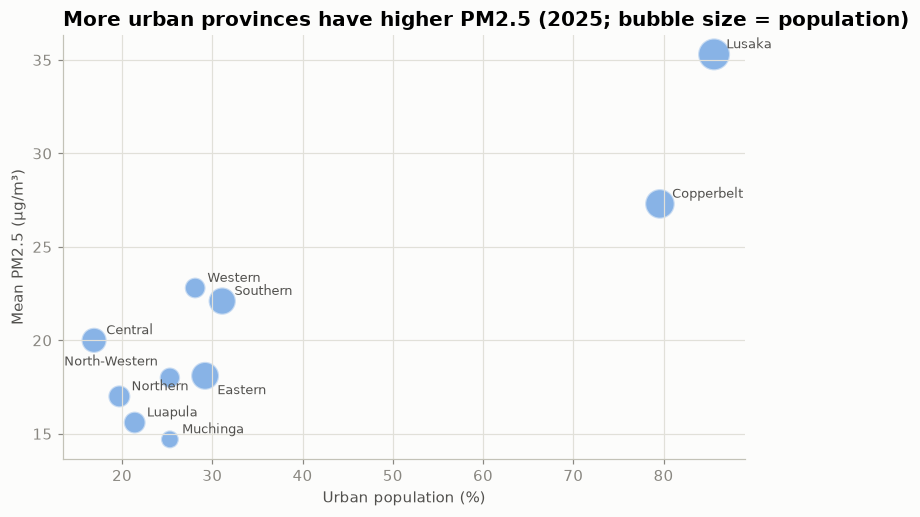

In [13]:
a25 = annual[annual["year"] == 2025]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(a25["urban_population_pct"], a25["mean_pm25_ugm3"],
          s=a25["population"] / 8000,  # bubble area ∝ population
          color=BLUE, alpha=0.55, edgecolor="#fcfcfb", linewidth=1.5)
nudge = {"Eastern": (8, -12), "North-Western": (-8, 8)}
# move labels that would collide
for _, row in a25.iterrows():
   dx, dy = nudge.get(row["province"], (8, 4))
   ax.annotate(row["province"], (row["urban_population_pct"], row["mean_pm25_ugm3"]),
              xytext=(dx, dy), textcoords="offset points", fontsize=8.5, color=INK_SOFT,
              ha="right" if dx < 0 else "left")
ax.set_xlabel("Urban population (%)")
ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_title("More urban provinces have higher PM2.5 (2025; bubble size = population)")
ax.grid(axis="x", visible=True)
plt.show()

### Interpretation: Urbanization, PM2.5 and Population

**Purpose:** This bubble chart compares urban population
percentage, mean PM2.5 concentration, and provincial
population in the synthetic 2025 dataset.

**Observed pattern:** Provinces with higher urban population
percentages generally have higher PM2.5 concentrations.
Lusaka is approximately 85% urban with mean PM2.5 around
35 µg/m³. Muchinga is approximately 25% urban with mean
PM2.5 around 15 µg/m³.

**Design:** Horizontal position represents urban population
percentage, vertical position represents mean PM2.5, and
bubble area represents total provincial population.
Labels identify the provinces.

**Insight:** The chart reveals a positive association between
urbanization and PM2.5 while also showing population differences.

**Limitations:** Association does not establish causation.
Only ten provinces are compared, and annual averages hide
monthly variation. Bubble areas are harder to compare
precisely than positions. All values are synthetic.

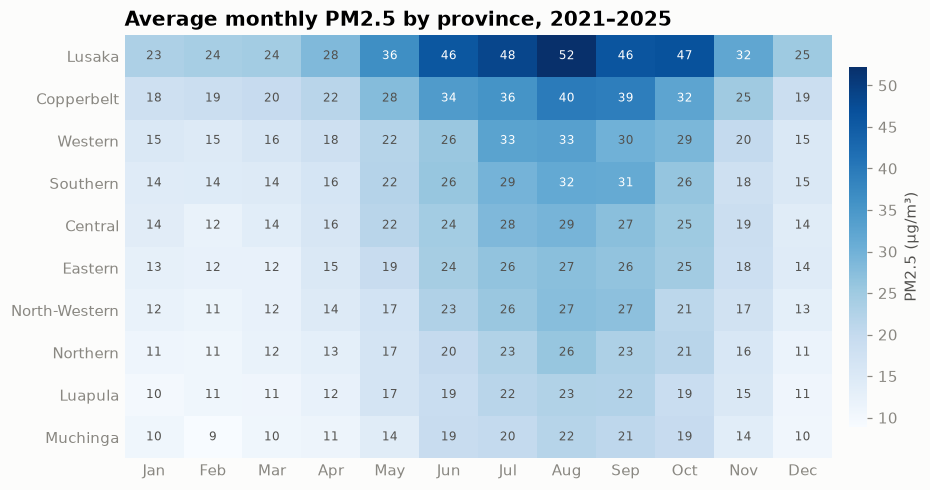

In [14]:
heat = (monthly.groupby(["province", "month"])["pm25_ugm3"].mean()
       .unstack("month"))
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

# most polluted on top
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")

ax.set_xticks(range(12), month_names)
ax.set_yticks(range(len(heat)), heat.index)
ax.grid(False)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)

# Write each value in its cell; use white text on dark cells
threshold = heat.values.max() * 0.6
for i in range(heat.shape[0]):
   for j in range(heat.shape[1]):
      v = heat.values[i, j]
      ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
             color="white" if v > threshold else INK_SOFT)

cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label("PM2.5 (µg/m³)")
cbar.outline.set_visible(False)
ax.set_title("Average monthly PM2.5 by province, 2021–2025")
plt.show()

### Interpretation: Monthly PM2.5 Across Provinces

**Purpose:** This heatmap compares average PM2.5 concentrations
by province and calendar month, using synthetic data from
2021–2025.

**Observed pattern:** Lusaka has the highest concentrations
throughout the year, reaching approximately 52 µg/m³ in August.
Concentrations across provinces are generally higher from
July to October and lower from November to March.
Muchinga and Luapula generally have comparatively low values.

**Design:** Rows represent provinces and columns represent
months. Darker blue indicates higher PM2.5 concentrations.
The colour bar gives the measurement scale, while cell
labels provide rounded values.

**Insight:** The heatmap reveals both provincial differences
and a shared seasonal pattern in one compact display.

**Limitations:** Each cell averages the same calendar month
across five years, hiding year-to-year differences.
Values are rounded, and the synthetic data do not establish
actual pollution conditions or their causes.

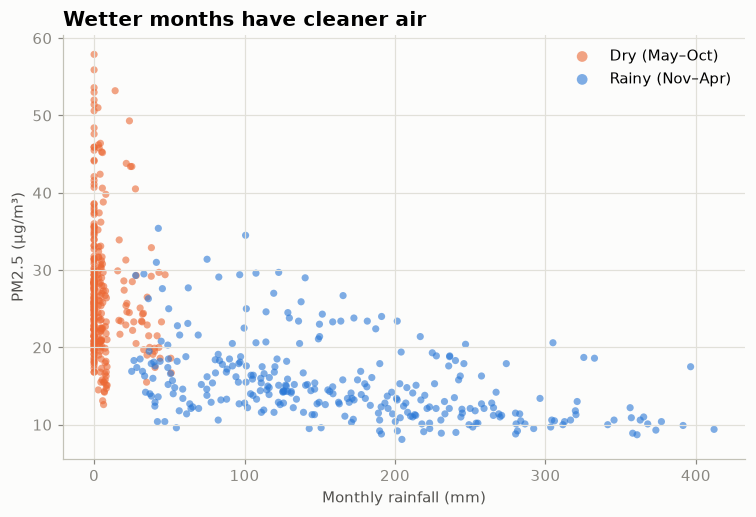

Correlation between rainfall and PM2.5: r = -0.61


In [15]:
rainy_months = [11, 12, 1, 2, 3, 4]
monthly["season"] = np.where(monthly["month"].isin(rainy_months),
                     "Rainy (Nov–Apr)", "Dry (May–Oct)")
fig, ax = plt.subplots(figsize=(8, 5))
for season, colour in [("Dry (May–Oct)", ORANGE), ("Rainy (Nov–Apr)", BLUE)]:
    sub = monthly[monthly["season"] == season]
    ax.scatter(sub["rainfall_mm"], sub["pm25_ugm3"], s=22, color=colour, alpha=0.6,
             edgecolor="none", label=season)
ax.set_xlabel("Monthly rainfall (mm)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Wetter months have cleaner air")
ax.grid(axis="x", visible=True)
ax.legend(loc="upper right", markerscale=1.5)
plt.show()
r = monthly["rainfall_mm"].corr(monthly["pm25_ugm3"])
print(f"Correlation between rainfall and PM2.5: r = {r:.2f}")

### Interpretation: Rainfall and PM2.5

**Purpose:** This scatterplot examines the association between
monthly rainfall and PM2.5 concentrations across provinces
from 2021–2025.

**Observed pattern:** Higher rainfall is generally associated
with lower PM2.5 concentrations. The Pearson correlation
is approximately −0.61, indicating a negative association.

Dry-season observations cluster near low rainfall values
and show a wide range of PM2.5 concentrations, with some
above 50 µg/m³. At rainfall above 200 mm, most observations
have PM2.5 below approximately 20 µg/m³.

**Design:** Each point represents one province-month.
Horizontal position shows rainfall, vertical position shows
PM2.5, and colour distinguishes rainy and dry seasons.

**Limitations:** Correlation does not establish causation.
Pooling provinces and months can conceal differences between
groups. Pearson correlation summarizes linear association,
while the plotted pattern is curved. All values are synthetic.

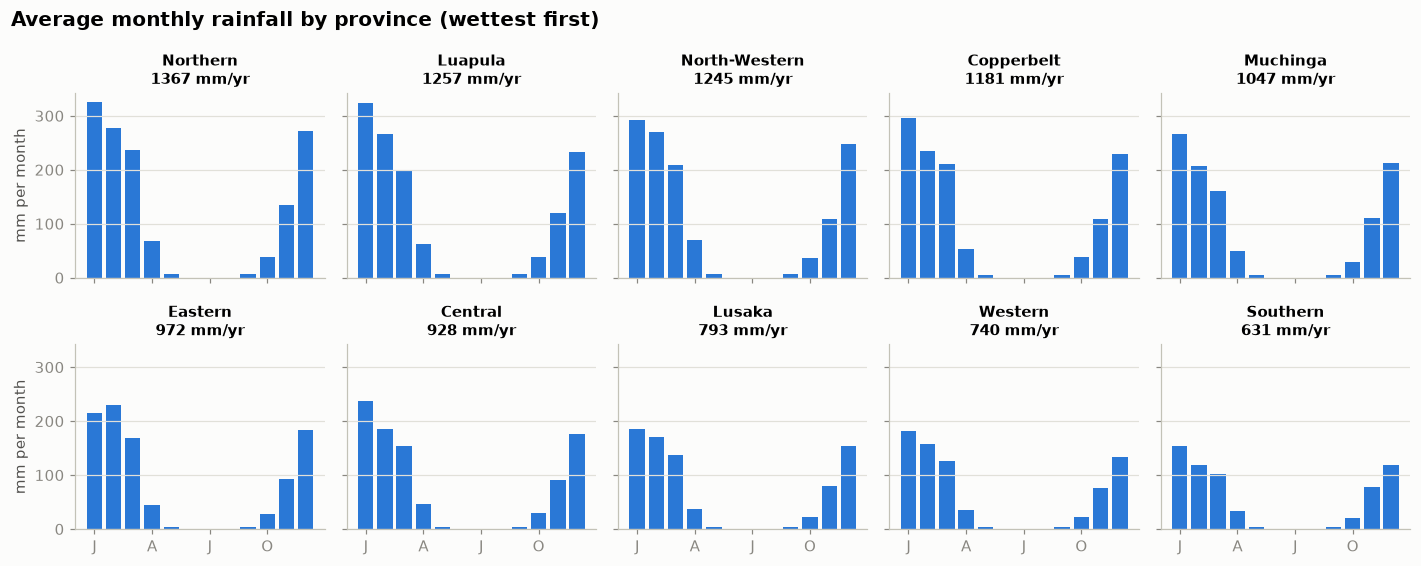

In [16]:
rain_cycle = monthly.groupby(["province", "month"])["rainfall_mm"].mean().unstack(0)
order = rain_cycle.sum().sort_values(ascending=False).index # wettest first

fig, axes = plt.subplots(2, 5, figsize=(13, 5.2), sharex=True, sharey=True)
for ax, name in zip(axes.flat, order):
    ax.bar(rain_cycle.index, rain_cycle[name], color=BLUE, width=0.8)
    ax.set_title(f"{name}\n{rain_cycle[name].sum():.0f} mm/yr", fontsize=10, loc="center")
    ax.set_xticks([1, 4, 7, 10], ["J", "A", "J", "O"])

for ax in axes[:, 0]:
    ax.set_ylabel("mm per month")

fig.suptitle("Average monthly rainfall by province (wettest first)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

### Interpretation: Provincial Rainfall Seasonal Patterns

**Purpose:** These small-multiple charts compare average
monthly rainfall patterns across ten provinces using
synthetic data from 2021–2025.

**Observed pattern:** Northern Province has the highest average
annual rainfall, approximately 1,367 mm, while Southern
Province has the lowest, approximately 631 mm. Rainfall is
generally concentrated around November–March, with very
little during May–September.

**Design:** Each province has its own panel, with common
horizontal and vertical scales supporting fair comparison.
Panels are ordered from highest to lowest average annual
rainfall. The annual figure is the sum of the twelve
monthly averages.

**Insight:** Provinces share a similar seasonal cycle but
differ substantially in rainfall amounts.

**Limitations:** Five-year averages hide differences between
individual years and unusual months. All values are synthetic
and do not establish actual provincial rainfall conditions.

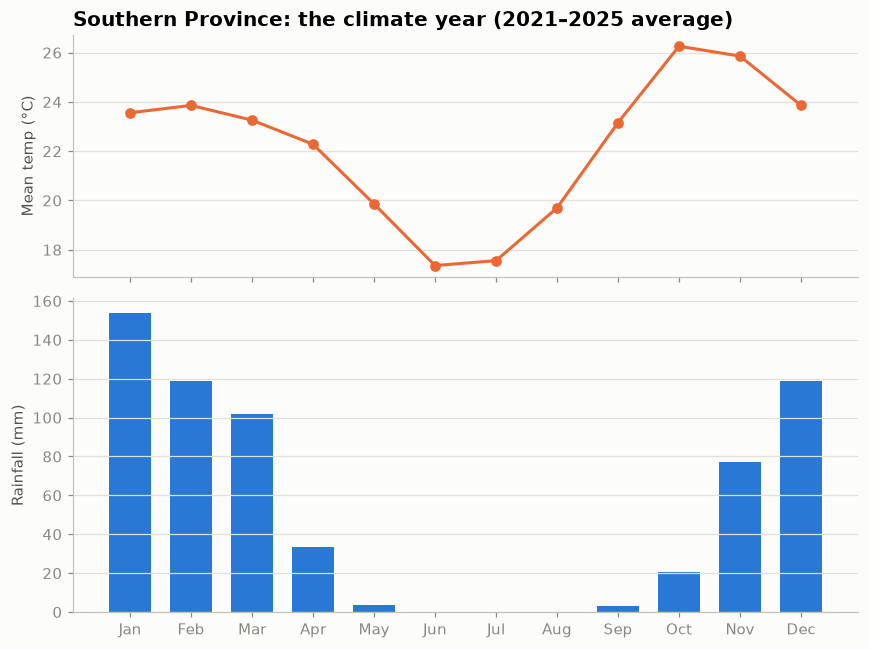

In [17]:
region = "Southern"
cyc = (monthly[monthly["province"] == region]
      .groupby("month")[["rainfall_mm", "temp_mean_c"]]
      .mean())
fig, (ax_t, ax_r) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                                height_ratios=[1, 1.3])
ax_t.plot(cyc.index, cyc["temp_mean_c"], color=ORANGE, marker="o")
ax_t.set_ylabel("Mean temp (°C)")
ax_t.set_title(f"{region} Province: the climate year (2021–2025 average)")

ax_r.bar(cyc.index, cyc["rainfall_mm"], color=BLUE, width=0.7)
ax_r.set_ylabel("Rainfall (mm)")
ax_r.set_xticks(range(1, 13), month_names)

fig.tight_layout()
plt.show()

### Interpretation: Southern Province Temperature and Rainfall

**Purpose:** These panels compare Southern Province’s average
monthly temperature and rainfall using synthetic data
from 2021–2025.

**Observed pattern:** Mean temperature reaches its highest
point in October, but October does not have the highest
rainfall. Rainfall is concentrated around November–March,
with very low amounts during the middle of the year.

**Insight:** The hottest period and the wettest period
do not coincide. The shared monthly timeline makes this
difference easy to identify.

**Design:** Temperature and rainfall occupy separate panels
with their own units and vertical scales. A shared horizontal
axis allows comparison of seasonal timing without mixing
degrees Celsius and millimetres on one scale.

**Limitations:** Five-year monthly averages hide differences
between individual years. The chart describes seasonal
patterns without establishing causation. All values
are synthetic.

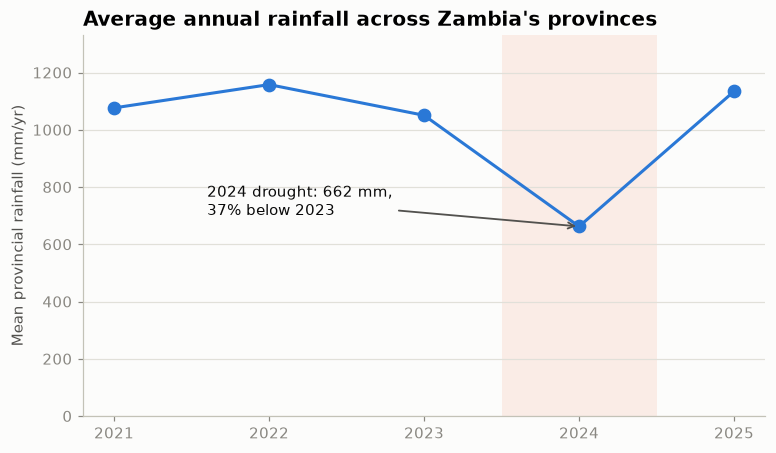

In [18]:
national = annual.groupby("year")["total_rainfall_mm"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(national.index, national.values, color=BLUE, marker="o", markersize=8)
ax.axvspan(2023.5, 2024.5, color=ORANGE, alpha=0.10, linewidth=0)
ax.annotate(f"2024 drought: {national[2024]:.0f} mm,\n"
          f"{(1 - national[2024] / national[2023]) * 100:.0f}% below 2023",
          xy=(2024, national[2024]), xytext=(2021.6, national[2024] + 40),
          arrowprops=dict(arrowstyle="->", color=INK_SOFT, linewidth=1.2),
          fontsize=10, color=INK)

ax.set_xticks(national.index)
ax.set_ylim(0, national.max() * 1.15)
ax.set_ylabel("Mean provincial rainfall (mm/yr)")
ax.set_title("Average annual rainfall across Zambia's provinces")
plt.show()

### Interpretation: Average Annual Rainfall Across Provinces

**Purpose:** This line chart shows the unweighted mean of
annual provincial rainfall totals from 2021 to 2025
in the synthetic dataset.

**Observed pattern:** Mean provincial rainfall falls to
approximately 662 mm in 2024, about 37% below its 2023
level. It rises again in 2025. The 2024 value is the
lowest of the five years displayed.

**Design:** Connected points show changes between years.
The shaded band and annotation draw attention to the
simulated 2024 drought year. The vertical axis starts
at zero, providing context for the size of the decline.

**Limitations:** Each province receives equal weight,
regardless of its area. This is not an area-weighted
national rainfall estimate. Averaging also hides
provincial differences. All values are synthetic.

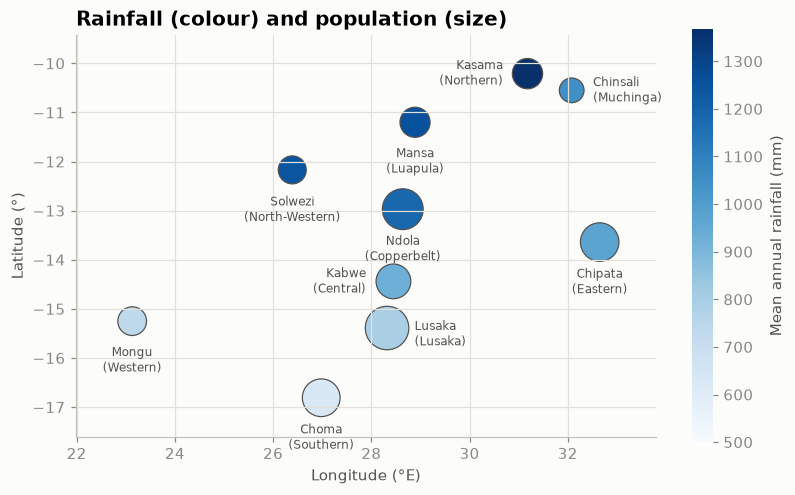

In [19]:
geo = provinces.merge(
     annual.groupby("province", as_index=False)[["total_rainfall_mm", "population"]].mean(),
     on="province")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sc = ax.scatter(geo["longitude"], geo["latitude"], c=geo["total_rainfall_mm"], cmap="Blues",
               s=geo["population"] / 4000, vmin=500, edgecolor=INK_SOFT, linewidth=0.8)

# Default: label below the circle. Some capitals sit close together, so place
# those labels to one side instead (offset in points, horizontal alignment).
place = {"Kasama": ((-16, 0), "right"), "Chinsali": ((14, 0), "left"),
         "Kabwe": ((-18, 0), "right"), "Lusaka": ((18, -4), "left")}
for _, row in geo.iterrows():
   (dx, dy), ha = place.get(row["capital"], ((0, -16), "center"))
   ax.annotate(f"{row['capital']}\n({row['province']})", (row["longitude"], row["latitude"]),
            xytext=(dx, dy), textcoords="offset points", ha=ha,
            va="top" if dy < -10 else "center", fontsize=8, color=INK_SOFT)

cbar = fig.colorbar(sc, ax=ax, shrink=0.75)
cbar.set_label("Mean annual rainfall (mm)")
cbar.outline.set_visible(False)
ax.set_aspect("equal")

# one degree east = one degree north
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°)")
ax.grid(axis="x", visible=True)
ax.margins(0.12)
ax.set_title("Rainfall (colour) and population (size)")
plt.show()

### Interpretation: Geographic Patterns in Rainfall and Population

**Purpose:** This chart displays provincial rainfall and
population averages for 2021–2025 at the coordinates
of each provincial capital.

**Observed pattern:** Northern locations, including Kasama,
Mansa, and Solwezi, generally have darker blue bubbles,
indicating higher mean annual rainfall. Choma and Mongu
have lighter bubbles, indicating lower rainfall.

Lusaka and Copperbelt have relatively large bubbles,
representing larger average provincial populations.

**Design:** Position represents capital coordinates, colour
represents mean annual provincial rainfall, and bubble
area represents average provincial population.

**Limitations:** The values describe entire provinces,
not just their capitals. Capital locations do not show
provincial boundaries or variation within provinces.
Bubble areas are difficult to compare precisely without
a size legend. All values are synthetic.

**SAVE YOUR FIGURES TO FILES**
Goal: export a chart for a report or slide.

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(rain_2025["province"], rain_2025["total_rainfall_mm"], color=BLUE, height=0.65)
ax.bar_label(bars, fmt="%.0f", padding=4, color=INK_SOFT, fontsize=9)
ax.set_title("Total rainfall by province, 2025 (synthetic data)")
ax.set_xlabel("Rainfall (mm per year)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)

fig.savefig("rainfall_2025.png", dpi=200, bbox_inches="tight")
fig.savefig("rainfall_2025.pdf", bbox_inches="tight")
plt.close(fig)

# close it so it isn't also displayed below
import os
for name in ["rainfall_2025.png", "rainfall_2025.pdf"]:
   print(f"{name}: {os.path.getsize(name) / 1024:.0f} KB")

rainfall_2025.png: 72 KB
rainfall_2025.pdf: 25 KB


**PART 4 PRACTICE AND CHECK YOUR WORK**

**Line Plot (Steps 10-11: monthly mean temperature (temp_mean_c) for Copperbelt,
Lusaka and Western on one chart with direct labels. Which province is warmest in October?**

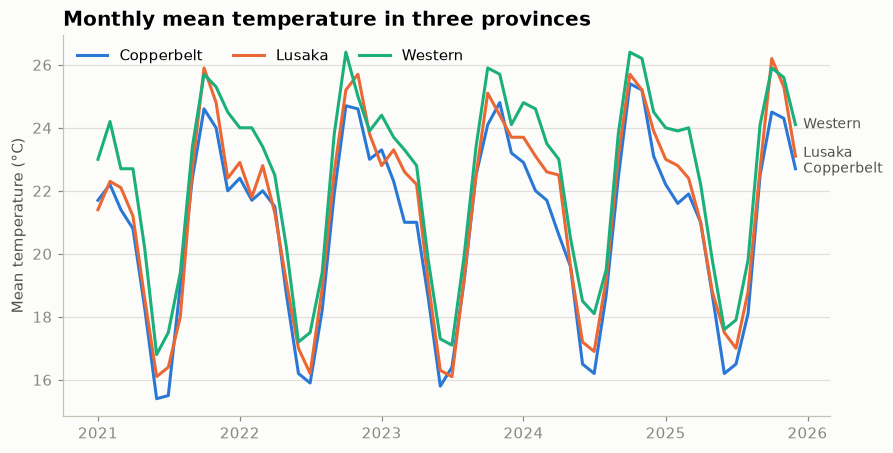

Average October temperature, 2021–2025 (°C):
province
Western       26.06
Lusaka        25.62
Copperbelt    24.66
Name: temp_mean_c, dtype: float64


In [21]:
import matplotlib.pyplot as plt

chosen = ["Copperbelt", "Lusaka", "Western"]

fig, ax = plt.subplots()

ends = []

for name, colour in zip(chosen, SERIES):
    sub = monthly[monthly["province"] == name]

    ax.plot(
        sub["date"],
        sub["temp_mean_c"],
        color=colour,
        label=name
    )

    ends.append([sub["temp_mean_c"].iloc[-1], name])

# Direct labels at the right-hand end
ends.sort()

for i in range(1, len(ends)):
    ends[i][0] = max(ends[i][0], ends[i - 1][0] + 0.5)

x_label = monthly["date"].max() + pd.Timedelta(days=20)

for y, name in ends:
    ax.text(
        x_label,
        y,
        name,
        color=INK_SOFT,
        va="center",
        fontsize=9
    )

ax.set_title("Monthly mean temperature in three provinces")
ax.set_ylabel("Mean temperature (°C)")
ax.legend(loc="upper left", ncols=3)

plt.show()

october_temperatures = (
    monthly[
        (monthly["month"] == 10)
        & monthly["province"].isin(
            ["Copperbelt", "Lusaka", "Western"]
        )
    ]
    .groupby("province")["temp_mean_c"]
    .mean()
    .sort_values(ascending=False)
)

print("Average October temperature, 2021–2025 (°C):")
print(october_temperatures.round(2))

### Interpretation: Monthly Temperatures in Three Provinces

**Purpose:** This line chart compares monthly mean temperatures
in Copperbelt, Lusaka, and Western from 2021 to 2025.

**Observed pattern:** All three provinces show recurring
seasonal changes, with cooler middle-year months followed
by warmer periods. Western generally has higher temperatures,
while Copperbelt generally has lower temperatures. Lusaka
exceeds Western during some individual peaks.

**Design:** Different colours and direct labels identify
the provinces. A shared temperature scale allows comparison
of their levels and seasonal timing.

**Limitations:** Overlapping lines make small differences
difficult to judge. The October summary table provides
a more precise comparison for that month. All data
are synthetic.

**October comparison:** Western has the highest five-year
average October mean temperature among the three selected
provinces, at 26.06°C. This describes the average across
2021–2025, rather than the temperature in every individual
October.

**Sorted Bars showing Population Growth from 2021 to 2025 as a percentage**

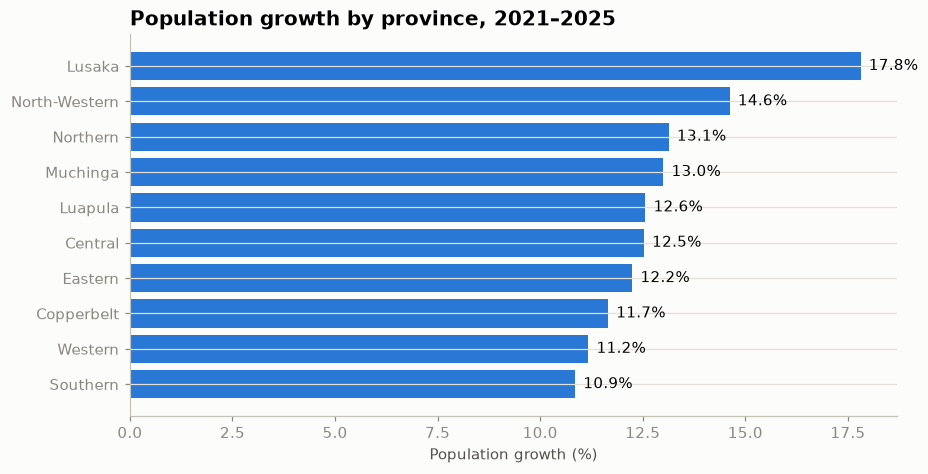

In [22]:
pop_2021 = annual[annual["year"] == 2021][
    ["province", "population"]
].rename(columns={"population": "pop_2021"})

pop_2025 = annual[annual["year"] == 2025][
    ["province", "population"]
].rename(columns={"population": "pop_2025"})

growth = pop_2021.merge(pop_2025, on="province")

growth["growth_pct"] = (
    (growth["pop_2025"] - growth["pop_2021"])
    / growth["pop_2021"]
    * 100
)

growth = growth.sort_values("growth_pct")

fig, ax = plt.subplots()

ax.barh(
    growth["province"],
    growth["growth_pct"],
    color=BLUE
)

ax.set_title("Population growth by province, 2021–2025")
ax.set_xlabel("Population growth (%)")

for i, value in enumerate(growth["growth_pct"]):
    ax.text(
        value + 0.2,
        i,
        f"{value:.1f}%",
        va="center"
    )

plt.show()

### Interpretation: Provincial Population Growth, 2021–2025

**Purpose:** This chart compares the percentage increase
in provincial populations between 2021 and 2025.

**Observed pattern:** Lusaka has the highest growth at 17.8%,
while Southern has the lowest at 10.9%. The difference
is 6.9 percentage points. All provinces show positive growth.

**Design:** Sorted horizontal bars make the ranking easy
to follow. Percentage labels allow precise comparisons.

**Insight:** Percentage growth compares changes relative
to each province’s starting population. It does not show
the absolute number of people added.

**Limitations:** Comparing only the starting and ending
years hides changes within the period. The chart does
not explain the causes of growth. All data are synthetic.

3. **Calculate yearly average SO₂**

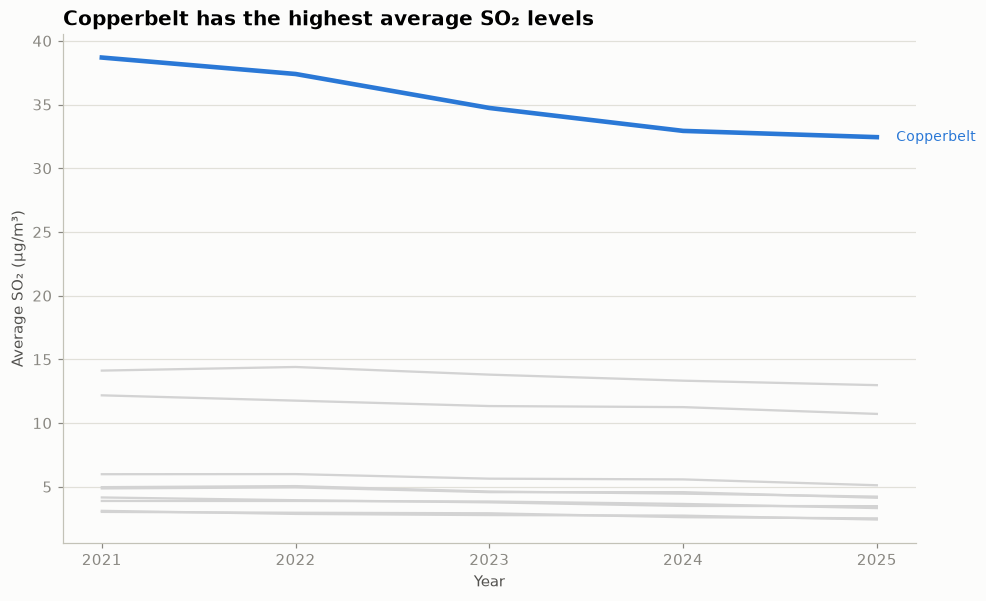

In [23]:
# Question 3: Highlight yearly average SO2
# All provinces are grey; Copperbelt is highlighted

import matplotlib.pyplot as plt

# Calculate yearly average SO2 for each province
yearly_so2 = (
    monthly
    .groupby(["province", "year"], as_index=False)["so2_ugm3"]
    .mean()
)

fig, ax = plt.subplots(figsize=(10, 6))

# Plot every province in grey
for name in yearly_so2["province"].unique():
    sub = yearly_so2[yearly_so2["province"] == name]

    ax.plot(
        sub["year"],
        sub["so2_ugm3"],
        color="lightgrey",
        linewidth=1.5
    )

# Highlight Copperbelt in colour
copperbelt = yearly_so2[
    yearly_so2["province"] == "Copperbelt"
]

ax.plot(
    copperbelt["year"],
    copperbelt["so2_ugm3"],
    color=BLUE,
    linewidth=3
)

# Direct label for Copperbelt
ax.text(
    copperbelt["year"].iloc[-1] + 0.1,
    copperbelt["so2_ugm3"].iloc[-1],
    "Copperbelt",
    color=BLUE,
    va="center",
    fontsize=9
)

# Finding-based title
ax.set_title("Copperbelt has the highest average SO₂ levels")

ax.set_xlabel("Year")
ax.set_ylabel("Average SO₂ (µg/m³)")
ax.set_xticks(yearly_so2["year"].unique())

plt.show()

### Interpretation: Provincial SO₂ Concentrations

**Purpose:** This chart compares annual average SO₂
concentrations across provinces from 2021 to 2025,
with Copperbelt highlighted.

**Observed pattern:** Copperbelt’s average SO₂ concentration
decreases overall but remains above the other provinces
in every year shown.

**Insight:** A decrease over time does not necessarily
change a province’s ranking relative to other provinces.

**Design:** A coloured line highlights Copperbelt, while
grey lines provide comparison. The shared scale allows
direct comparison of concentrations in µg/m³.

**Limitations:** Annual averages hide monthly variation.
The chart does not establish the causes of the differences
or decline. All values are synthetic teaching data.

**Question 4: Province × year heatmap of total rainfall**

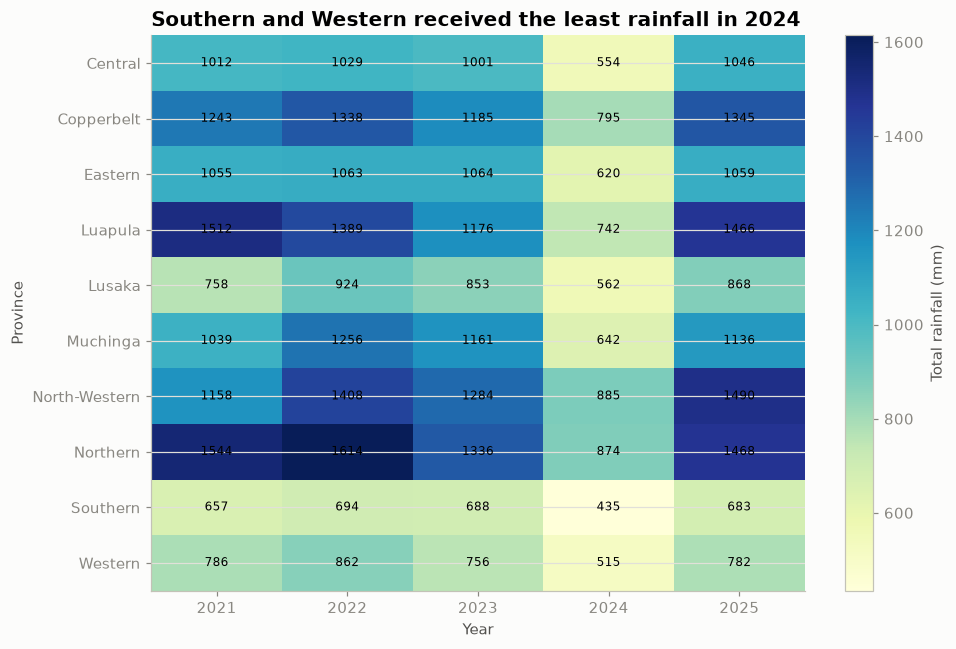

         province  year  rainfall_mm
43       Southern  2024        434.8
48        Western  2024        514.8
3         Central  2024        553.8
23         Lusaka  2024        561.6
13        Eastern  2024        619.9
28       Muchinga  2024        642.5
18        Luapula  2024        741.8
8      Copperbelt  2024        794.6
38       Northern  2024        873.6
33  North-Western  2024        885.2


In [24]:
# Question 4: Province × year heatmap of total rainfall

import matplotlib.pyplot as plt

# Calculate total rainfall for each province in each year
yearly_rainfall = (
    monthly
    .groupby(["province", "year"], as_index=False)["rainfall_mm"]
    .sum()
)

# Reshape the data: provinces = rows, years = columns
rainfall_heatmap = yearly_rainfall.pivot(
    index="province",
    columns="year",
    values="rainfall_mm"
)

# Create the heatmap
fig, ax = plt.subplots(figsize=(9, 6))

heatmap = ax.imshow(
    rainfall_heatmap.values,
    cmap="YlGnBu",
    aspect="auto"
)

# Set year labels on x-axis
ax.set_xticks(range(len(rainfall_heatmap.columns)))
ax.set_xticklabels(rainfall_heatmap.columns)

# Set province labels on y-axis
ax.set_yticks(range(len(rainfall_heatmap.index)))
ax.set_yticklabels(rainfall_heatmap.index)

# Add rainfall values inside the heatmap cells
for i in range(len(rainfall_heatmap.index)):
    for j in range(len(rainfall_heatmap.columns)):
        value = rainfall_heatmap.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=8
        )

# Add colour bar
cbar = fig.colorbar(heatmap, ax=ax)
cbar.set_label("Total rainfall (mm)")

# Labels and finding-based title
ax.set_title("Southern and Western received the least rainfall in 2024")
ax.set_xlabel("Year")
ax.set_ylabel("Province")

plt.tight_layout()
plt.show()

# Find the provinces hardest hit in 2024
rainfall_2024 = (
    yearly_rainfall[yearly_rainfall["year"] == 2024]
    .sort_values("rainfall_mm")
)

print(rainfall_2024)

### Interpretation: Annual Rainfall by Province and Year

**Purpose:** This heatmap compares annual rainfall totals
across ten provinces from 2021 to 2025.

**Observed pattern:** The 2024 column contains lower rainfall
totals than the other years across all provinces.
Southern has the lowest 2024 total, approximately 435 mm,
followed by Western at approximately 515 mm.

**Design:** Rows represent provinces and columns represent
years. Colour indicates rainfall totals, while cell labels
provide rounded values. A common colour scale supports
comparison across the entire chart.

**Insight:** The chart reveals both the widespread simulated
2024 rainfall decline and differences between provinces.

**Limitations:** Having the lowest rainfall total does not
necessarily mean experiencing the largest proportional
decline or greatest drought impact. Annual totals also
hide monthly patterns. All values are synthetic.

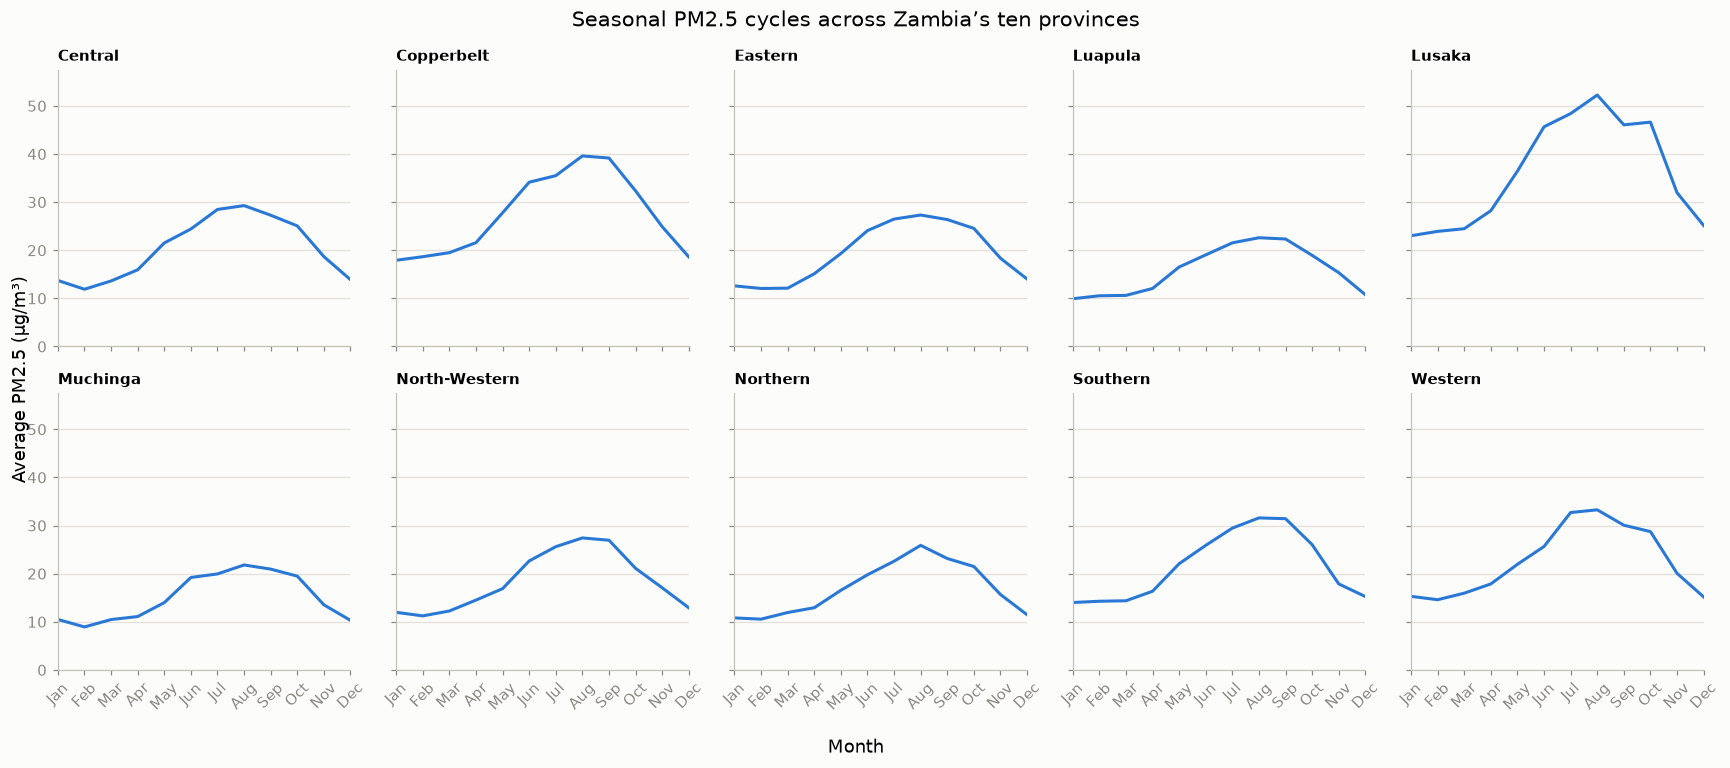

In [25]:
# Question 5: Small multiples of PM2.5 seasonal cycles

import matplotlib.pyplot as plt

# Calculate average monthly PM2.5 for each province
pm_cycle = (
    monthly
    .groupby(["province", "month"])["pm25_ugm3"]
    .mean()
    .unstack(0)
)

# Month labels
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Create a 2 × 5 grid
fig, axes = plt.subplots(
    2,
    5,
    figsize=(16, 7),
    sharex=True,
    sharey=True
)

# Convert the grid of axes into one sequence
axes = axes.flatten()

# Draw one province in each panel
for ax, name in zip(axes, pm_cycle.columns):

    ax.plot(
        pm_cycle.index,
        pm_cycle[name],
        color=BLUE,
        linewidth=2
    )

    ax.set_title(name, fontsize=10)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, rotation=45)
    ax.set_xlim(1, 12)
    ax.set_ylim(bottom=0)

# Overall title and shared axis labels
# Use one shared scale that includes every province's peak.
upper_limit = pm_cycle.max().max() * 1.10

for ax in axes:
    ax.set_ylim(0, upper_limit)
fig.suptitle(
    "Seasonal PM2.5 cycles across Zambia’s ten provinces",
    fontsize=14
)

fig.supxlabel("Month")
fig.supylabel("Average PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

### Interpretation: Provincial PM2.5 Seasonal Cycles

**Purpose:** These panels compare average monthly PM2.5
patterns across ten provinces using synthetic 2021–2025 data.

**Observed pattern:** Concentrations generally rise toward
the middle of the year, peak around July–September, and
decline toward December. Lusaka has higher concentrations
than the other provinces.

**Design:** Each province occupies a separate panel, avoiding
overlapping lines. All panels use the same vertical scale,
allowing fair comparisons of concentration levels.

**Comparison:** Separate panels make individual seasonal
patterns easier to examine. The earlier highlighted chart
is more effective when the main purpose is to compare
Lusaka directly against the other provinces.

**Limitations:** Five-year monthly averages hide variation
between years. Small panels make exact values harder
to read. All data are synthetic.

**6. Three problems with the classmate's chart**

a). Too many bright colours: Ten brightly coloured provincial rainfall lines create visual clutter.It becomes difficult to follow an individual province and distinguish all ten colours reliably.

b). Too many overlapping lines: Monthly rainfall varies considerably, so placing all ten provinces on one chart creates a “spaghetti plot”.
Provincial seasonal patterns can become hidden by overlapping lines.

c). ax.twinx() makes interpretation difficult: Rainfall and temperature have different units and scales. Putting them on separate y-axes in the same panel can make unrelated movements appear visually comparable.
The interpretation can also change depending on the limits chosen for the two axes.


Redesign

A clearer solution is to use two vertically stacked plots with the same x-axis: rainfall above and temperature below. Use small multiples for the ten provinces rather than ten bright lines.

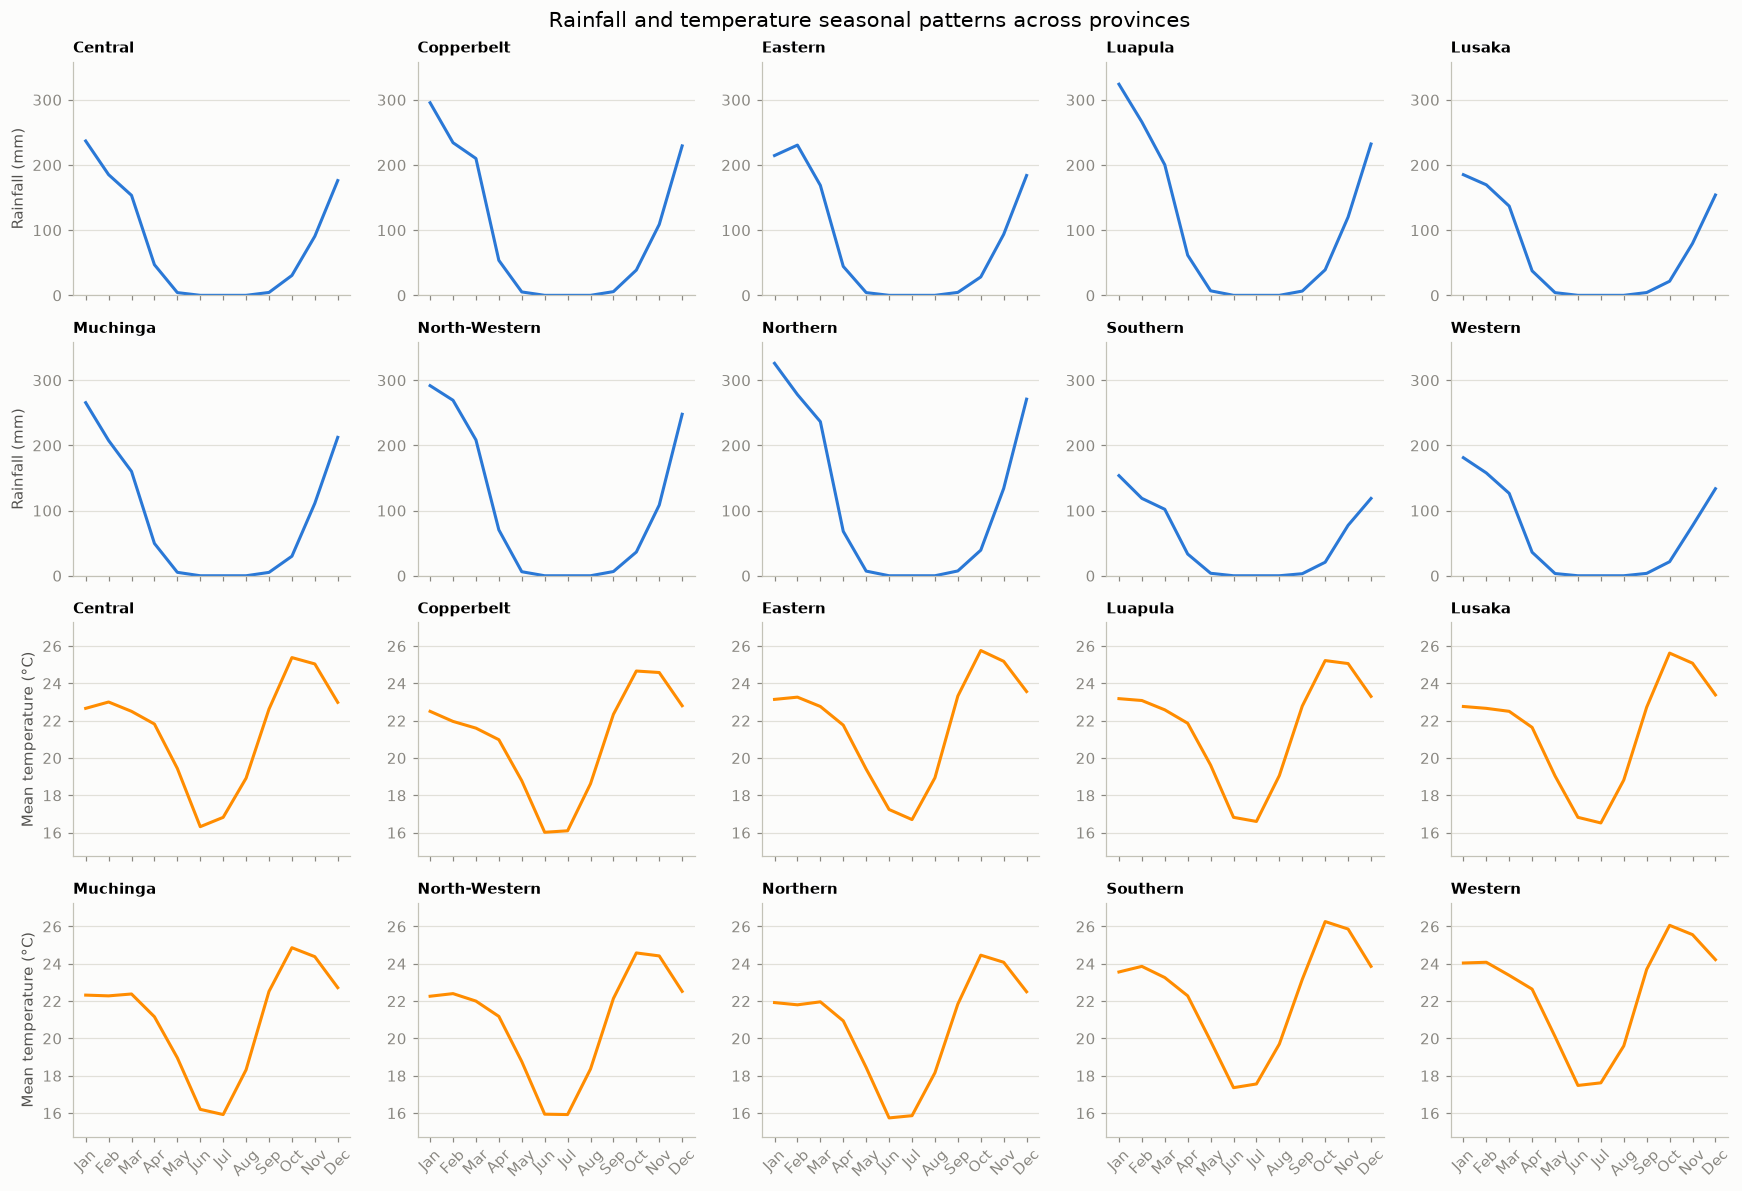

In [26]:
# Critique redesign:
# Small multiples with rainfall and temperature separated

import matplotlib.pyplot as plt

# Calculate seasonal monthly averages
seasonal = (
    monthly
    .groupby(["province", "month"], as_index=False)
    [["rainfall_mm", "temp_mean_c"]]
    .mean()
)

provinces = sorted(seasonal["province"].unique())

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# 4 rows × 5 columns:
# top 2 rows = rainfall
# bottom 2 rows = temperature
fig, axes = plt.subplots(
    4,
    5,
    figsize=(16, 11),
    sharex=True
)

# Rainfall small multiples
for ax, province in zip(axes[:2].flatten(), provinces):

    sub = seasonal[seasonal["province"] == province]

    ax.plot(
        sub["month"],
        sub["rainfall_mm"],
        color=BLUE,
        linewidth=2
    )

    ax.set_title(province, fontsize=10)
    ax.set_ylim(bottom=0)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, rotation=45)


# Temperature small multiples
for ax, province in zip(axes[2:].flatten(), provinces):

    sub = seasonal[seasonal["province"] == province]

    ax.plot(
        sub["month"],
        sub["temp_mean_c"],
        color="darkorange",
        linewidth=2
    )

    ax.set_title(province, fontsize=10)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, rotation=45)


# Add row labels
axes[0, 0].set_ylabel("Rainfall (mm)")
axes[1, 0].set_ylabel("Rainfall (mm)")
axes[2, 0].set_ylabel("Mean temperature (°C)")
axes[3, 0].set_ylabel("Mean temperature (°C)")

# Use consistent scales within each measurement.
rainfall_upper = seasonal["rainfall_mm"].max() * 1.10
temperature_lower = seasonal["temp_mean_c"].min() - 1
temperature_upper = seasonal["temp_mean_c"].max() + 1

for ax in axes[:2].flat:
    ax.set_ylim(0, rainfall_upper)

for ax in axes[2:].flat:
    ax.set_ylim(temperature_lower, temperature_upper)

# Use consistent scales within each measurement.
rainfall_upper = seasonal["rainfall_mm"].max() * 1.10
temperature_lower = seasonal["temp_mean_c"].min() - 1
temperature_upper = seasonal["temp_mean_c"].max() + 1

for ax in axes[:2].flat:
    ax.set_ylim(0, rainfall_upper)

for ax in axes[2:].flat:
    ax.set_ylim(temperature_lower, temperature_upper)

fig.suptitle(
    "Rainfall and temperature seasonal patterns across provinces",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Interpretation: Redesigning a Crowded Climate Chart

**Purpose:** Compare provincial seasonal rainfall and
temperature patterns without overlapping ten coloured
lines or using two vertical axes in one panel.

**Observed pattern:** Rainfall is concentrated around
the wetter months, while temperatures generally fall
during the middle of the year and rise toward October.

**Design:** Separate panels distinguish provinces and
measurements. Rainfall panels share one rainfall scale,
and temperature panels share one temperature scale.
A common monthly axis supports comparison of timing.

**Strength:** The design reduces overlap and makes provincial
patterns easier to inspect.

**Limitation:** Twenty panels require considerable space,
and readers must look between panels to compare variables.
These five-year averages hide variation between years.
All data are synthetic.

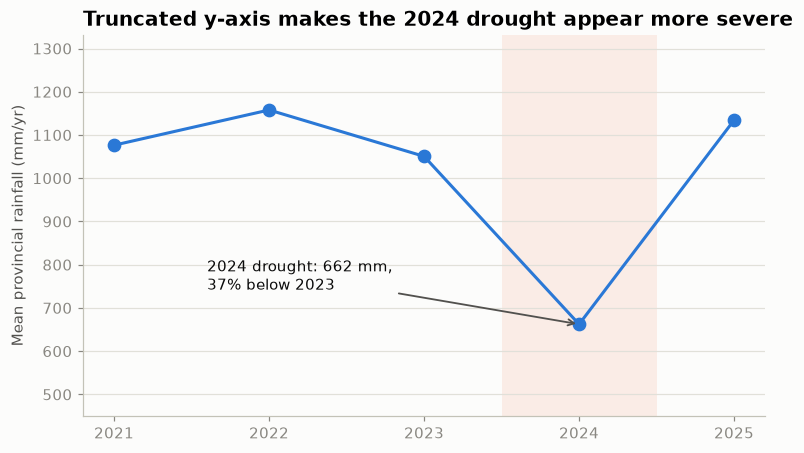

In [27]:
# Honesty: Step 23 with y-axis starting at 450 mm

import matplotlib.pyplot as plt

# Calculate national mean annual rainfall
national = annual.groupby("year")["total_rainfall_mm"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))

# Plot annual rainfall
ax.plot(
    national.index,
    national.values,
    color=BLUE,
    marker="o",
    markersize=8
)

# Highlight 2024 drought
ax.axvspan(
    2023.5,
    2024.5,
    color=ORANGE,
    alpha=0.10,
    linewidth=0
)

# Annotate the drought
ax.annotate(
    f"2024 drought: {national[2024]:.0f} mm,\n"
    f"{(1 - national[2024] / national[2023]) * 100:.0f}% below 2023",
    xy=(2024, national[2024]),
    xytext=(2021.6, national[2024] + 80),
    arrowprops=dict(
        arrowstyle="->",
        color=INK_SOFT,
        linewidth=1.2
    ),
    fontsize=10,
    color=INK
)

ax.set_xticks(national.index)

# IMPORTANT: truncated y-axis starts at 450 mm
ax.set_ylim(450, national.max() * 1.15)

ax.set_ylabel("Mean provincial rainfall (mm/yr)")
ax.set_title("Truncated y-axis makes the 2024 drought appear more severe")

plt.show()

### Interpretation: The Effect of a Truncated Vertical Axis

**Purpose:** This example demonstrates how axis limits
influence the visual impression of change.

**Observation:** Starting the vertical axis at 450 mm
makes the 2024 rainfall decline occupy a larger share
of the plotting height than in the zero-baseline version.
The underlying data remain unchanged: mean provincial
rainfall in 2024 is approximately 662 mm, about 37%
below 2023.

**Design lesson:** A truncated axis can reveal variation
in a line chart, but its limits must be clear. Readers
should check numerical values before judging the
magnitude of a change.

**Limitation:** This chart shows an unweighted mean across
provinces and hides provincial differences. All data
are synthetic.

# Additional Visualizations

These visualizations extend the supplied tutorial using
new chart types and analytical questions.

## 1. Distribution of Monthly Mean Temperatures

**Question:** How do typical temperatures and their
distributions differ between four selected provinces?

A violin plot shows the distribution’s shape. Wider sections
indicate a greater concentration of observations around
those temperatures. All data are synthetic.

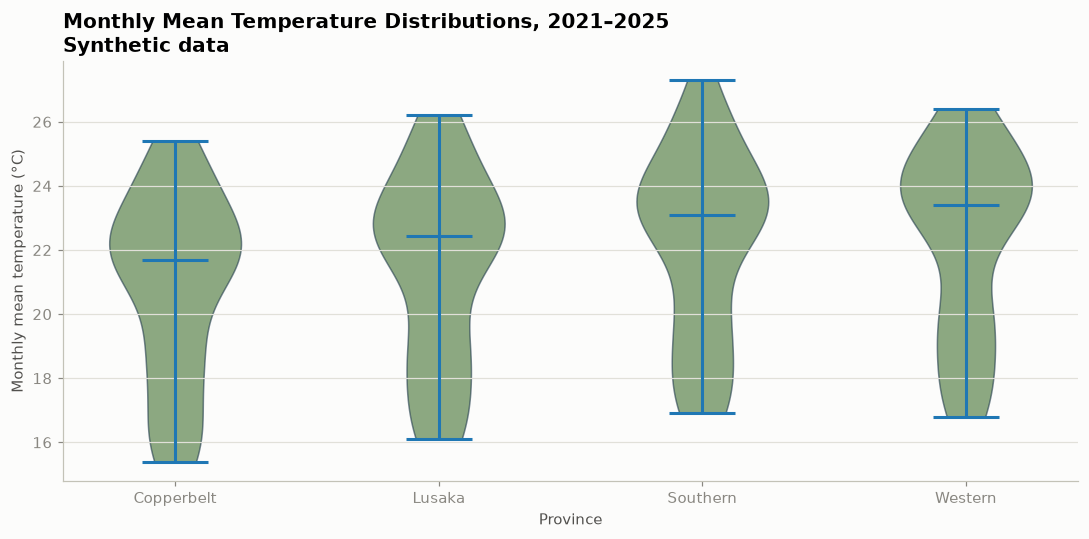

,count,median,min,max
province,,,,
Western,60,23.40,16.8,26.4
Southern,60,23.10,16.9,27.3
Lusaka,60,22.45,16.1,26.2
Copperbelt,60,21.70,15.4,25.4


In [28]:
selected_provinces = [
    "Copperbelt", "Lusaka", "Southern", "Western"
]

temperature_groups = [
    monthly.loc[
        monthly["province"] == province,
        "temp_mean_c"
    ].dropna().to_numpy()
    for province in selected_provinces
]

fig, ax = plt.subplots(figsize=(10, 5))

violins = ax.violinplot(
    temperature_groups,
    positions=range(1, len(selected_provinces) + 1),
    showmedians=True,
    showextrema=True
)

for body in violins["bodies"]:
    body.set_facecolor("#427030")
    body.set_edgecolor("#233d4d")
    body.set_alpha(0.6)

ax.set_xticks(
    range(1, len(selected_provinces) + 1),
    selected_provinces
)

ax.set_title(
    "Monthly Mean Temperature Distributions, 2021–2025\n"
    "Synthetic data"
)
ax.set_xlabel("Province")
ax.set_ylabel("Monthly mean temperature (°C)")

plt.tight_layout()
plt.show()

temperature_summary = (
    monthly[
        monthly["province"].isin(selected_provinces)
    ]
    .groupby("province")["temp_mean_c"]
    .agg(["count", "median", "min", "max"])
    .sort_values("median", ascending=False)
)

display(temperature_summary.round(2))

### Interpretation: Monthly Mean Temperature Distributions

**Observed pattern:** Western has the highest median monthly
mean temperature at 23.40°C, followed by Southern at 23.10°C,
Lusaka at 22.45°C, and Copperbelt at 21.70°C. Each province
contributes 60 monthly observations.

Southern has the highest individual monthly mean temperature,
27.3°C, despite Western having the highest median.

**Design:** Vertical position represents temperature.
Wider sections indicate greater estimated concentration
of observations. The internal horizontal marker shows
the median, while the endpoints show the minimum and maximum.

**Insight:** The chart distinguishes typical temperature
levels from extremes and reveals distribution shapes
that a single average would conceal.

**Limitations:** Violin shapes depend on smoothing.
Pooling months hides seasonal order, and violin width
does not represent population size. All data are synthetic.

## 2. Cumulative Distribution of Monthly Rainfall

**Question:** What percentage of months has rainfall
at or below a given amount in Northern, Lusaka,
and Southern provinces?

An empirical cumulative distribution function (ECDF)
shows these percentages without grouping observations
into histogram bins.

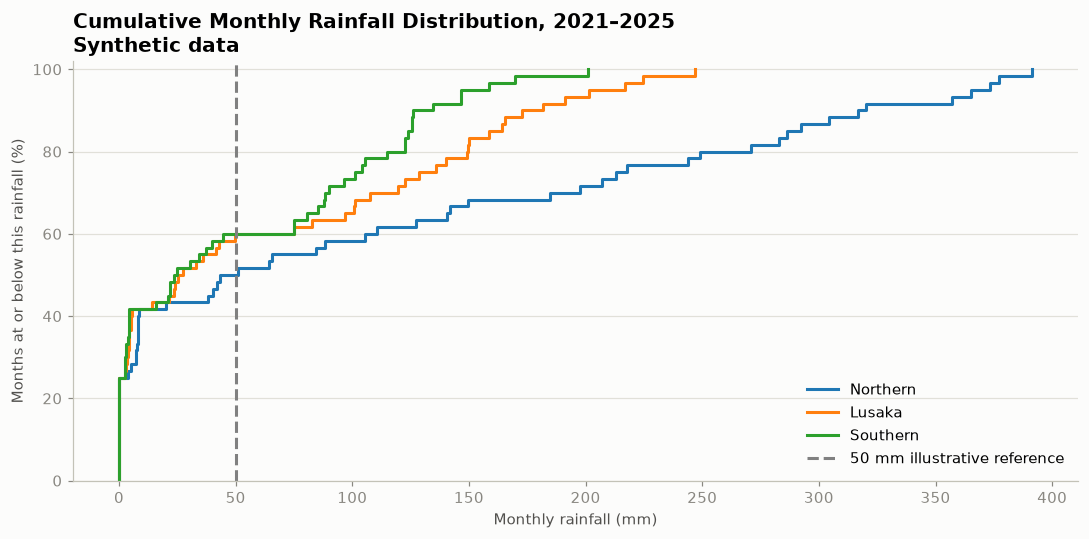

,Province,Months,Months with rainfall ≤ 50 mm (%)
0,Northern,60,50.0
1,Lusaka,60,60.0
2,Southern,60,60.0


In [29]:
comparison_provinces = ["Northern", "Lusaka", "Southern"]
threshold_mm = 50
results = []

fig, ax = plt.subplots(figsize=(10, 5))

for province in comparison_provinces:
    values = np.sort(
        monthly.loc[
            monthly["province"] == province,
            "rainfall_mm"
        ].dropna().to_numpy()
    )

    percentages = np.arange(1, len(values) + 1) / len(values) * 100

    ax.step(
        np.r_[values[0] - 0.1, values],
        np.r_[0, percentages],
        where="post",
        label=province,
        linewidth=2
    )

    results.append({
        "Province": province,
        "Months": len(values),
        "Months with rainfall ≤ 50 mm (%)":
            (values <= threshold_mm).mean() * 100
    })

ax.axvline(
    threshold_mm,
    color="grey",
    linestyle="--",
    label="50 mm illustrative reference"
)

ax.set_title(
    "Cumulative Monthly Rainfall Distribution, 2021–2025\n"
    "Synthetic data"
)
ax.set_xlabel("Monthly rainfall (mm)")
ax.set_ylabel("Months at or below this rainfall (%)")
ax.set_ylim(0, 102)
ax.legend()

plt.tight_layout()
plt.show()

rainfall_ecdf_summary = pd.DataFrame(results)
display(rainfall_ecdf_summary.round(1))

### Interpretation: Cumulative Monthly Rainfall Distribution

**Observed pattern:** Monthly rainfall is at or below 50 mm
in 50% of Northern’s observations, compared with 60% for
both Lusaka and Southern. These represent 30, 36, and
36 months respectively out of 60 observations per province.

**Insight:** Lusaka and Southern have a larger proportion
of lower-rainfall months at this reference value.
Their equal percentages at 50 mm do not mean their
complete rainfall distributions are identical.

**Design:** Horizontal position represents monthly rainfall.
Vertical position shows the percentage of observations
at or below that amount. Separate curves identify provinces.

**Limitations:** The 50 mm reference is illustrative,
not an official drought threshold. The chart removes
chronological order, so it cannot identify consecutive
dry months. All data are synthetic.

## 3. Change in Provincial SO₂: 2021 versus 2025

**Question:** How did average SO₂ concentrations change
between 2021 and 2025 in each province?

A dumbbell chart connects two values for each province.
The endpoints show the concentrations in the two years,
and connector length shows the magnitude of change.

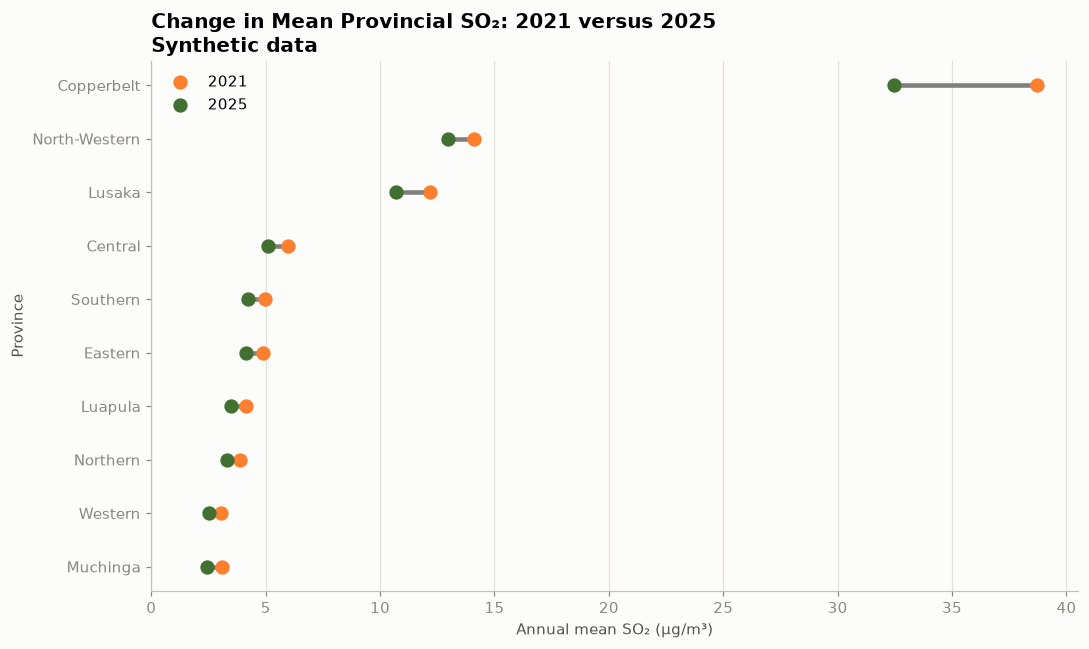

year,2021,2025,change_2025_minus_2021
province,,,
Muchinga,3.11,2.43,-0.68
Western,3.02,2.52,-0.51
Northern,3.88,3.32,-0.56
Luapula,4.16,3.47,-0.68
Eastern,4.87,4.13,-0.73
Southern,4.97,4.23,-0.74
Central,5.98,5.12,-0.87
Lusaka,12.18,10.72,-1.46
North-Western,14.12,12.98,-1.14


Province with largest absolute change: Copperbelt
Change (µg/m³): -6.25


In [30]:
so2_comparison = (
    monthly[monthly["year"].isin([2021, 2025])]
    .groupby(["province", "year"])["so2_ugm3"]
    .mean()
    .unstack("year")
    .dropna(subset=[2021, 2025])
    .sort_values(2025)
)

positions = np.arange(len(so2_comparison))

fig, ax = plt.subplots(figsize=(10, 6))

ax.hlines(
    positions,
    xmin=so2_comparison[[2021, 2025]].min(axis=1),
    xmax=so2_comparison[[2021, 2025]].max(axis=1),
    color="grey",
    linewidth=3
)

ax.scatter(
    so2_comparison[2021],
    positions,
    color="#fe7f2d",
    s=70,
    label="2021",
    zorder=3
)

ax.scatter(
    so2_comparison[2025],
    positions,
    color="#427030",
    s=70,
    label="2025",
    zorder=3
)

ax.set_yticks(positions, so2_comparison.index)
ax.set_xlim(left=0)
ax.set_title(
    "Change in Mean Provincial SO₂: 2021 versus 2025\n"
    "Synthetic data"
)
ax.set_xlabel("Annual mean SO₂ (µg/m³)")
ax.set_ylabel("Province")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.legend()

plt.tight_layout()
plt.show()

so2_comparison["change_2025_minus_2021"] = (
    so2_comparison[2025] - so2_comparison[2021]
)

display(so2_comparison.round(2))

largest_change = (
    so2_comparison["change_2025_minus_2021"]
    .abs()
    .idxmax()
)

print("Province with largest absolute change:", largest_change)
print(
    "Change (µg/m³):",
    round(
        so2_comparison.loc[
            largest_change, "change_2025_minus_2021"
        ],
        2
    )
)

### Interpretation: Changes in Provincial SO₂

**Observed pattern:** Copperbelt has the largest absolute
change in annual mean SO₂ between 2021 and 2025,
decreasing by 6.25 µg/m³.

**Design:** Orange points represent 2021 and green points
represent 2025. Connecting lines show the magnitude
of change. A green point to the left of its orange
point indicates a decrease.

**Insight:** The chart makes endpoint differences easy
to compare across provinces. A large decrease does
not necessarily mean a province has a low final
concentration.

**Limitations:** Comparing two years hides intermediate
fluctuations. Annual averages conceal monthly variation,
and the chart does not establish why concentrations
changed. All data are synthetic.

# Conclusion

This notebook explored seasonal patterns, provincial
differences, distributions, and relationships in synthetic
Zambian climate, air-quality, and population data.

The tutorial analysis showed recurring rainfall and
temperature cycles, a simulated rainfall decline in 2024,
and a negative association between rainfall and PM2.5.
The rainfall–PM2.5 correlation was approximately −0.61;
this association does not establish causation.

Three additional visualization types extended the analysis:

- The violin plot showed that Western had the highest
  median monthly mean temperature among four selected
  provinces, at 23.40°C. Southern had the highest individual
  monthly mean value, at 27.3°C.
- The ECDF showed that rainfall was at or below 50 mm
  in 50% of Northern’s months and 60% of months in
  both Lusaka and Southern.
- The dumbbell chart showed that Copperbelt had the
  largest absolute SO₂ change between 2021 and 2025,
  a decrease of 6.25 µg/m³.

These examples demonstrate how different chart types
answer different questions. Findings apply only to
the synthetic teaching dataset and should not be
presented as actual conditions in Zambia.

# Acknowledgement

The starting notebook and dataset were supplied through:
https://github.com/malichi978/Malichi_Zambia_Charts

This submission builds on that material through revised
interpretations, chart corrections, and additional analyses.